# SoccerNet-GSR: frames, posições e cinemática descritiva

Anotações públicas v1.3; não são previsões de um rastreador executado nesta tarefa. Não há alvo clínico ou de fadiga. Consulte o README para cobertura do download, controles e limites.

In [1]:
import json, gzip, hashlib
import pandas as pd
from IPython.display import display, Markdown, Image
from pipeline import ROOT, load_points, run
manifest = json.loads((ROOT / 'results/download_manifest.json').read_text(encoding='utf-8'))
assert manifest['download_complete']
if not (ROOT / 'results/summary.json').exists():
    run()
summary = json.loads((ROOT / 'results/summary.json').read_text(encoding='utf-8'))
print('Commit:', manifest['revision'])
display(pd.DataFrame(manifest['splits']).T)
print('Arquivos de anotações:', len(manifest['files']))

Commit: 3cc710eb6d53a23350a3d2863311c1c0a2e645d7


,archive_bytes,archive_lfs_sha256,annotation_files,annotation_compressed_bytes,bytes_transferred_this_run
train,9755097159,f216ebed0347f5af52ee7d975a9b5f6f33b5370bdbed75...,57,190998873,199062623
valid,11169497921,d60e517e0bfbce83d46a2805842d73bc98bbb65e84ba76...,58,191594621,199827622
test,8845186210,ac40080fadaebf3474477889576662de7970cae0cb375d...,49,142488038,149402668


Arquivos de anotações: 164


## Fonte real e junção

`annotations.image_id → images.image_id` é validada como muitos para um. `split + clip + track_id` identifica uma trajetória local, sem vincular identidades entre clips.

In [2]:
item = manifest['files'][0]
source = ROOT / 'data/raw' / item['split'] / (item['clip'] + '.json.gz')
with gzip.open(source, 'rb') as f:
    data = f.read()
assert hashlib.sha256(data).hexdigest() == item['sha256_json']
obj = json.loads(data)
print(obj['info'])
points, fps, missing = load_points(obj)
print('FPS:', fps, '| Anotações sem coordenadas:', missing)
display(points.head())

{'version': '1.3', 'game_id': '4', 'id': '060', 'num_tracklets': '26', 'action_position': '895', 'action_class': 'Kick-off', 'visibility': 'visible', 'game_time_start': '1 - 00:00', 'game_time_stop': '1 - 00:30', 'clip_start': '0', 'clip_stop': '30000', 'name': 'SNGS-060', 'im_dir': 'img1', 'frame_rate': 25, 'seq_length': 750, 'im_ext': '.jpg'}
FPS: 25.0 | Anotações sem coordenadas: 0


,image_id,track_id,role,team,jersey,x_m,y_m,frame,coordinate_qc
0,1060000001,1,player,left,10,-0.305316,24.100112,1,True
15,1060000002,1,player,left,10,-0.306147,24.103057,2,True
30,1060000003,1,player,left,10,-0.307796,24.108930,3,True
45,1060000004,1,player,left,10,-0.310235,24.117704,4,True
60,1060000005,1,player,left,10,-0.313412,24.129328,5,True


## Resultados e controles

Velocidade e aceleração são derivadas retrospectivamente das posições anotadas em segmentos contíguos. Limites cinemáticos são controles exploratórios de qualidade, não critérios clínicos.

In [3]:
display(Markdown((ROOT / 'results/RESULTADOS.md').read_text(encoding='utf-8')))
tracks = pd.read_csv(ROOT / 'data/processed/tracklet_features.csv')
clips = pd.read_csv(ROOT / 'data/processed/clip_audit.csv')
assert not tracks.duplicated(['split','clip','track_id']).any()
assert not clips.duplicated(['split','clip']).any()
assert len(clips) == len(manifest['files'])
display(tracks.head())
display(clips.groupby('split')[['frames','motion_points_before_qc','motion_points_after_qc']].sum())

# Resultados executados - SoccerNet-GSR

Cruzamento de anotações de referência e frames; sem modelo de lesão/fadiga.

- Clips: 164; distribuição: {'test': 49, 'train': 57, 'valid': 58}.
- Frames declarados: 123,000; jogos representados: 9.
- Trajetórias locais: 3,481; com movimento utilizável: 3,454.
- Anotações de jogador/goleiro com coordenadas: 1,736,361.
- Anotações sem coordenadas no campo: 22,385.
- Pontos derivados antes/depois do controle cinemático: 1,625,340 / 1,610,694.
- Cobertura mediana por trajetória: 70.3% dos frames do clip.
- Mediana das velocidades médias por trajetória com movimento: 2.275 m/s.
- Mediana dos percentis 95 de velocidade por trajetória: 4.752 m/s.

Não são atletas únicos, médias de uma partida completa, estimativas validadas por GPS ou escores de fadiga/lesão.


,split,clip,track_id,role,team,frames_observed,frame_coverage_fraction,segments_analyzed,motion_points,usable_motion_points,observed_distance_m,connected_observation_s,mean_speed_m_s,p95_speed_m_s,p95_abs_tangential_accel_m_s2,native_difference_p95_speed_m_s
0,train,SNGS-060,1,player,left,578,0.770667,2,538,538,61.774655,21.44,2.880574,6.208680,4.169114,6.227053
1,train,SNGS-060,2,player,left,750,1.000000,1,730,730,85.659468,29.16,2.934362,5.198585,3.677182,5.260982
2,train,SNGS-060,3,player,right,360,0.480000,2,290,290,54.298049,11.52,4.695260,6.794014,3.956105,6.821875
3,train,SNGS-060,4,player,right,568,0.757333,3,508,508,54.357852,20.20,2.685340,6.456489,4.103029,6.472121
4,train,SNGS-060,5,player,right,482,0.642667,2,442,442,35.965181,17.60,2.040005,3.532358,2.745225,3.573375


,frames,motion_points_before_qc,motion_points_after_qc
split,,,
test,36750,442784,437948
train,42750,586548,581583
valid,43500,596008,591163


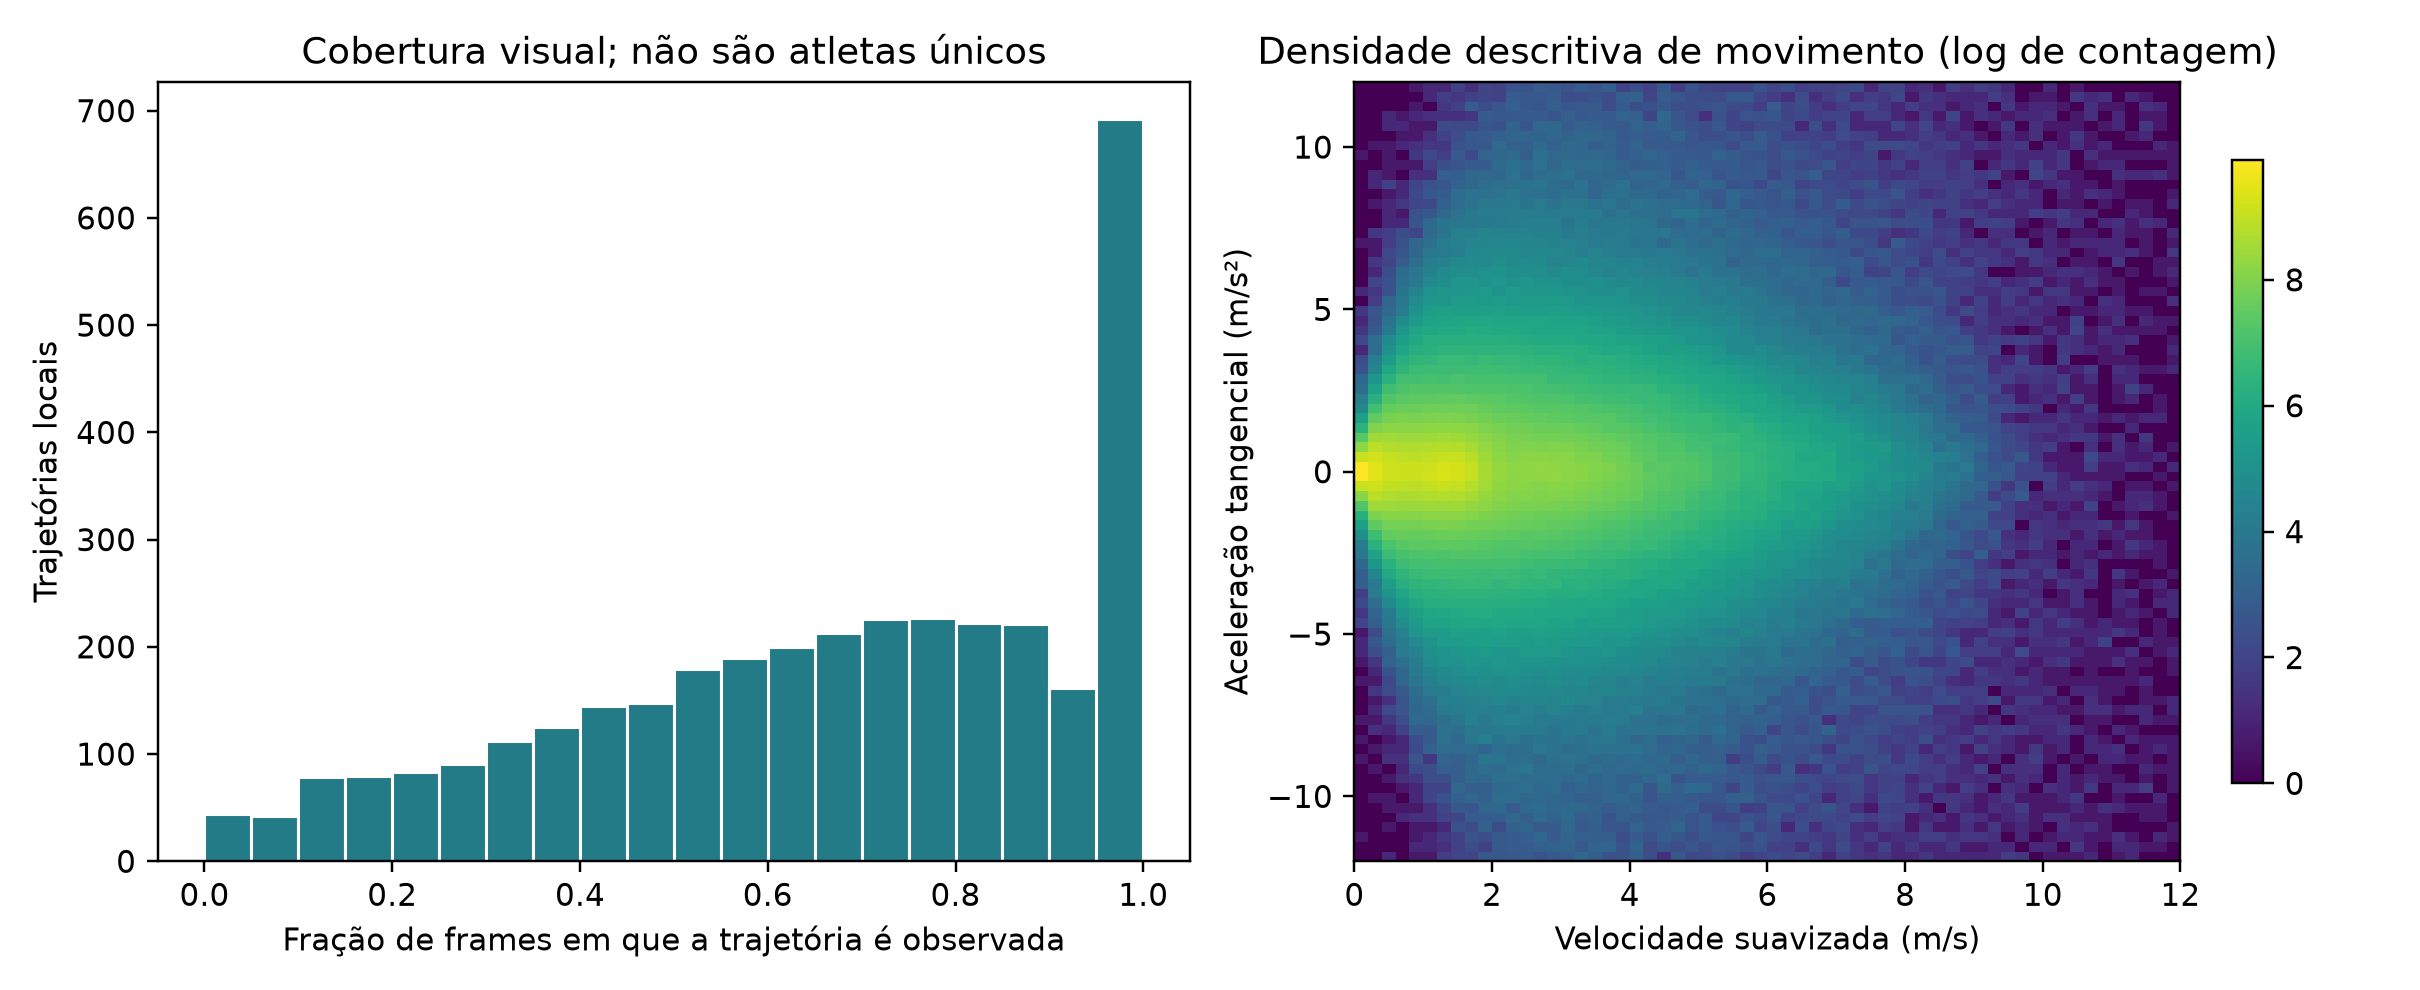

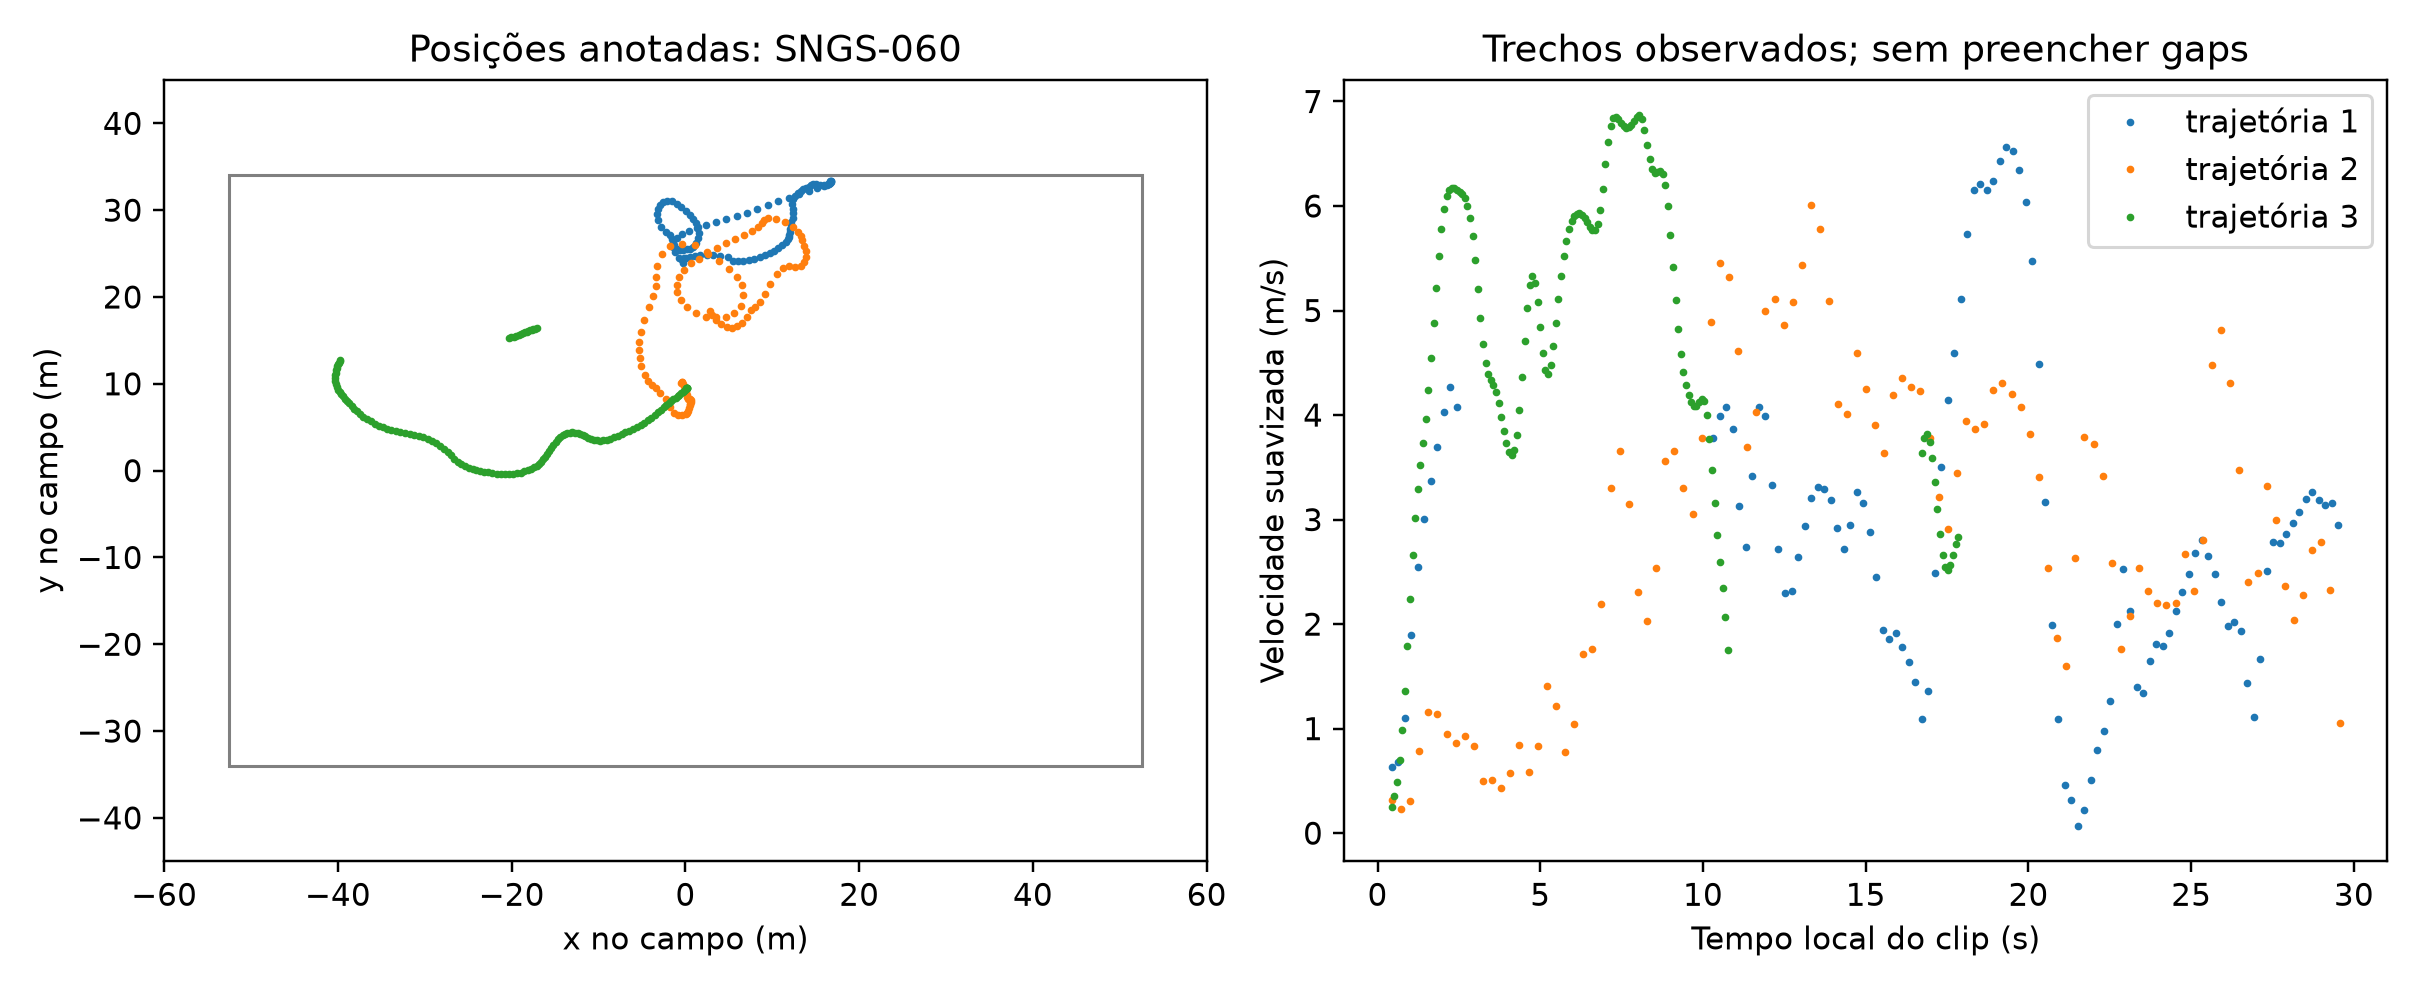

In [4]:
display(Image(filename=str(ROOT / 'figures/cobertura_e_movimento.png')))
display(Image(filename=str(ROOT / 'figures/exemplo_trajetorias.png')))

## Limites e reprodução

Sem frames de imagem, inferência automática, referência GPS, alvo de fadiga/lesão ou ligação clínica entre clips. Clips de 30 s não estabelecem evolução de fadiga de uma partida. O jogo adicional de 45 min de Bou não foi incluído. Para reproduzir, executar sequencialmente `download_annotations.py`, `test_kinematics.py` e `pipeline.py` nesta pasta; detalhes no README.